# Micro-Projeto de Visão Computacional — Reconhecimento de Gestos Manuais

**Capacitação em Visão Computacional** · IFPE · INPaR · Financiamento FACEPE

**Equipe:** Ana Luiza Leão

**Título:** Reconhecimento de Gestos Manuais com MediaPipe

## 1. Problema

O projeto tem como objetivo identificar três gestos manuais estáticos: mão aberta, punho fechado e polegar para cima. Para isso, serão utilizados pontos de referência da mão extraídos pelo MediaPipe, buscando classificar os gestos e avaliar o desempenho do sistema em diferentes exemplos.

## 2. Preparação

In [ ]:
%pip install mediapipe

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
from pathlib import Path
from google.colab import files
import zipfile
from PIL import Image
import urllib.request

print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("Bibliotecas importadas com sucesso!")

NumPy: 2.1.3
OpenCV: 5.0.0
MediaPipe: 1.1.0
Bibliotecas importadas com sucesso!


## 3. Dados

_De onde vêm as imagens ou vídeos? Quantos? Em que condições?_

**Exemplo:** a imagem de moedas em 6 condições (luz, sombra, ruído, desfoque). Gabarito: **24 moedas** em todas.

### Baixando dados

In [ ]:
arquivo_zip = files.upload()

for nome in arquivo_zip:
    with zipfile.ZipFile(nome, "r") as zip_ref:
        zip_ref.extractall("/content/dados")

print("Arquivos extraídos!")

Saving dados_gestos.zip to dados_gestos.zip
Arquivos extraídos!


Verificando arquivos contidos na pasta

In [ ]:
pasta_dados = Path("/content/dados")
extensoes = {".jpg", ".jpeg", ".png"}

imagens = [
    arquivo for arquivo in pasta_dados.rglob("*")
    if arquivo.is_file() and arquivo.suffix.lower() in extensoes
]

print("Total de imagens:", len(imagens))
print("\nImagens por categoria:")

for categoria in sorted({arquivo.parent.name for arquivo in imagens}):
    quantidade = sum(
        arquivo.parent.name == categoria for arquivo in imagens
    )
    print(f"{categoria}: {quantidade}")

Total de imagens: 15

Imagens por categoria:
mao_aberta: 5
positivo: 5
punho_fechado: 5


In [ ]:
pasta_dados = Path("/content/dados")

print("A pasta existe?", pasta_dados.exists())
print("\nPrimeiros arquivos encontrados:")

for arquivo in list(pasta_dados.rglob("*"))[:25]:
    print(arquivo)

A pasta existe? True

Primeiros arquivos encontrados:
/content/dados/punho_fechado
/content/dados/mao_aberta
/content/dados/positivo
/content/dados/punho_fechado/04.jpg
/content/dados/punho_fechado/03.jpg
/content/dados/punho_fechado/01.jpg
/content/dados/punho_fechado/05.jpg
/content/dados/punho_fechado/02.jpg
/content/dados/mao_aberta/04.jpg
/content/dados/mao_aberta/03.jpg
/content/dados/mao_aberta/01.jpg
/content/dados/mao_aberta/05.jpg
/content/dados/mao_aberta/02.jpg
/content/dados/positivo/04.jpg
/content/dados/positivo/03.jpg
/content/dados/positivo/01.jpg
/content/dados/positivo/05.jpg
/content/dados/positivo/02.jpg


### Visualizando amostra do arquivo

Formato: JPEG
Dimensões: (2944, 1324)
Modo: RGB


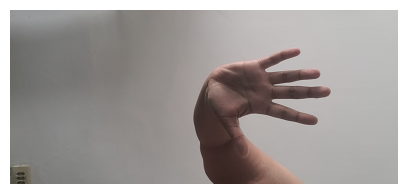

In [ ]:
arquivo = Path("/content/dados/mao_aberta/01.jpg")

imagem = Image.open(arquivo)

print("Formato:", imagem.format)
print("Dimensões:", imagem.size)
print("Modo:", imagem.mode)

plt.figure(figsize=(5, 5))
plt.imshow(imagem.convert("RGB"))
plt.axis("off")
plt.show()

### Baixando o modelo de mãos

In [ ]:
# 1. Baixar o modelo de detecção das mãos
modelo = Path("/content/hand_landmarker.task")

if not modelo.exists():
    url = (
        "https://storage.googleapis.com/mediapipe-models/"
        "hand_landmarker/hand_landmarker/float16/1/"
        "hand_landmarker.task"
    )
    urllib.request.urlretrieve(url, modelo)

print("Modelo disponível:", modelo.exists())

# 2. Configurar o detector
BaseOptions = mp.tasks.BaseOptions
Vision = mp.tasks.vision

opcoes = Vision.HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=str(modelo)),
    running_mode=Vision.RunningMode.IMAGE,
    num_hands=1
)

# 3. Carregar a foto e detectar a mão
caminho_foto = "/content/dados/mao_aberta/01.jpg"
imagem_bgr = cv2.imread(caminho_foto)

imagem_rgb = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2RGB)

imagem_mp = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=imagem_rgb
)

with Vision.HandLandmarker.create_from_options(opcoes) as detector:
    resultado = detector.detect(imagem_mp)

    print("Quantidade de mãos detectadas:", len(resultado.hand_landmarks))

    if resultado.hand_landmarks:
        pontos = resultado.hand_landmarks[0]
        print("Quantidade de pontos encontrados:", len(pontos))
        print("Primeiro ponto (pulso):", pontos[0])


Modelo disponível: True
Quantidade de mãos detectadas: 1
Quantidade de pontos encontrados: 21
Primeiro ponto (pulso): NormalizedLandmark(x=0.4251707196235657, y=0.46767115592956543, z=1.5148209513426991e-06, visibility=None, presence=None, name=None)


### Visualizando os 21 pontos

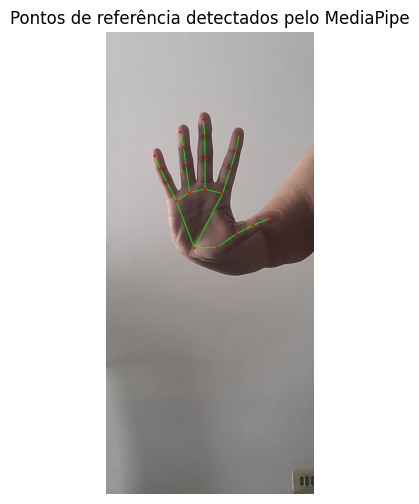

In [ ]:
imagem_anotada = imagem_rgb.copy()

conexoes = (
    mp.tasks.vision.HandLandmarksConnections.HAND_CONNECTIONS
)

altura, largura, _ = imagem_anotada.shape
pontos = resultado.hand_landmarks[0]

coordenadas = [
    (int(p.x * largura), int(p.y * altura))
    for p in pontos
]

# Desenhar as conexões entre os pontos
for conexao in conexoes:
    inicio = conexao.start
    fim = conexao.end

    x1, y1 = coordenadas[inicio], coordenadas[fim]
    cv2.line(
        imagem_anotada,
        x1,
        y1,
        (0, 255, 0),
        4
    )

# Desenhar os 21 pontos
for x, y in coordenadas:
    cv2.circle(imagem_anotada, (x, y), 8, (255, 0, 0), -1)

plt.figure(figsize=(12, 6))
plt.imshow(imagem_anotada)
plt.title("Pontos de referência detectados pelo MediaPipe")
plt.axis("off")
plt.show()


### Medindo a posição dos dedos

In [ ]:
# Índices dos pontos das pontas dos dedos e das articulações
dedos = {
    "polegar":  (4, 3),
    "indicador": (8, 6),
    "medio":     (12, 10),
    "anelar":    (16, 14),
    "mindinho":  (20, 18)
}

def analisar_dedos(pontos):
    medidas = {}

    for dedo, (ponta, articulacao) in dedos.items():
        x_ponta, y_ponta = pontos[ponta].x, pontos[ponta].y
        x_art, y_art = pontos[articulacao].x, pontos[articulacao].y

        medidas[dedo] = {
            "ponta_x": round(x_ponta, 3),
            "ponta_y": round(y_ponta, 3),
            "articulacao_y": round(y_art, 3)
        }

    return medidas

# Usar a detecção que já funcionou na foto da mão aberta
pontos = resultado.hand_landmarks[0]
medidas = analisar_dedos(pontos)

for dedo, valores in medidas.items():
    print(f"{dedo}: {valores}")


polegar: {'ponta_x': 0.789, 'ponta_y': 0.403, 'articulacao_y': 0.418}
indicador: {'ponta_x': 0.64, 'ponta_y': 0.223, 'articulacao_y': 0.296}
medio: {'ponta_x': 0.468, 'ponta_y': 0.19, 'articulacao_y': 0.272}
anelar: {'ponta_x': 0.358, 'ponta_y': 0.217, 'articulacao_y': 0.289}
mindinho: {'ponta_x': 0.235, 'ponta_y': 0.269, 'articulacao_y': 0.325}


### Extraindo medidas das 15 imagens

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import mediapipe as mp

pasta_dados = Path("/content/dados")
categorias = ["mao_aberta", "punho_fechado", "positivo"]

# Pontas dos dedos e articulações usadas na comparação
dedos = {
    "polegar": (4, 3),
    "indicador": (8, 6),
    "medio": (12, 10),
    "anelar": (16, 14),
    "mindinho": (20, 18)
}

linhas = []
Vision = mp.tasks.vision

opcoes = Vision.HandLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(
        model_asset_path="/content/hand_landmarker.task"
    ),
    running_mode=Vision.RunningMode.IMAGE,
    num_hands=1
)

with Vision.HandLandmarker.create_from_options(opcoes) as detector:
    for categoria in categorias:
        arquivos = sorted(
            p for p in (pasta_dados / categoria).glob("*")
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )

        for arquivo in arquivos:
            imagem = np.array(
                Image.open(arquivo).convert("RGB")
            )

            resultado_foto = detector.detect(
                mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=imagem
                )
            )

            linha = {
                "imagem": arquivo.name,
                "gesto_real": categoria,
                "detectou_mao": bool(resultado_foto.hand_landmarks)
            }

            if resultado_foto.hand_landmarks:
                pontos = resultado_foto.hand_landmarks[0]
                pulso = np.array([pontos[0].x, pontos[0].y])

                for dedo, (ponta, articulacao) in dedos.items():
                    p = np.array([pontos[ponta].x, pontos[ponta].y])
                    a = np.array([
                        pontos[articulacao].x,
                        pontos[articulacao].y
                    ])

                    dist_ponta = np.linalg.norm(p - pulso)
                    dist_art = np.linalg.norm(a - pulso)

                    linha[f"{dedo}_razao"] = round(
                        dist_ponta / max(dist_art, 1e-6), 3
                    )

            linhas.append(linha)

tabela_medidas = pd.DataFrame(linhas)

colunas = [
    "imagem", "gesto_real", "detectou_mao",
    "polegar_razao", "indicador_razao", "medio_razao",
    "anelar_razao", "mindinho_razao"
]

display(tabela_medidas[colunas])
print("\nTotal de imagens:", len(tabela_medidas))
print("Mãos detectadas:", int(tabela_medidas["detectou_mao"].sum()))


,imagem,gesto_real,detectou_mao,polegar_razao,indicador_razao,medio_razao,anelar_razao,mindinho_razao
0,01.jpg,mao_aberta,True,1.292,1.326,1.395,1.418,1.406
1,02.jpg,mao_aberta,True,1.312,1.320,1.387,1.373,1.356
2,03.jpg,mao_aberta,True,1.260,1.230,1.319,1.365,1.314
3,04.jpg,mao_aberta,True,1.290,1.298,1.394,1.365,1.335
4,05.jpg,mao_aberta,True,1.271,1.308,1.403,1.497,1.397
5,01.jpg,punho_fechado,True,0.946,0.789,0.683,0.638,0.773
6,02.jpg,punho_fechado,True,0.884,1.047,0.735,0.616,0.661
7,03.jpg,punho_fechado,True,0.960,0.724,0.645,0.580,0.626
8,04.jpg,punho_fechado,True,0.983,0.732,0.636,0.515,0.619
9,05.jpg,punho_fechado,True,1.002,0.739,0.737,0.641,0.883



Total de imagens: 15
Mãos detectadas: 15


## Criando o classificador

In [ ]:
import pandas as pd
import numpy as np

def classificar_gesto(linha):
    if not linha["detectou_mao"]:
        return "nao_detectado"

    polegar = linha["polegar_razao"]
    indicador = linha["indicador_razao"]
    medio = linha["medio_razao"]
    anelar = linha["anelar_razao"]
    mindinho = linha["mindinho_razao"]

    outros_dedos = [indicador, medio, anelar, mindinho]

    # Mão aberta: os quatro dedos estão relativamente estendidos
    if all(valor > 1.15 for valor in outros_dedos):
        return "mao_aberta"

    # Positivo: polegar estendido e os outros dedos dobrados
    if polegar > 1.05 and sum(
        valor < 0.95 for valor in outros_dedos
    ) >= 3:
        return "positivo"

    # Punho fechado: a maioria dos dedos está dobrada
    if sum(valor < 0.95 for valor in outros_dedos) >= 3:
        return "punho_fechado"

    return "indefinido"


tabela_avaliacao = tabela_medidas.copy()

tabela_avaliacao["gesto_previsto"] = tabela_avaliacao.apply(
    classificar_gesto, axis=1
)

tabela_avaliacao["acertou"] = (
    tabela_avaliacao["gesto_real"]
    == tabela_avaliacao["gesto_previsto"]
)

display(
    tabela_avaliacao[
        ["imagem", "gesto_real", "gesto_previsto", "acertou"]
    ]
)

acertos = int(tabela_avaliacao["acertou"].sum())
total = len(tabela_avaliacao)

print(f"\nAcertos: {acertos}/{total}")
print(f"Acurácia: {acertos / total:.1%}")


,imagem,gesto_real,gesto_previsto,acertou
0,01.jpg,mao_aberta,mao_aberta,True
1,02.jpg,mao_aberta,mao_aberta,True
2,03.jpg,mao_aberta,mao_aberta,True
3,04.jpg,mao_aberta,mao_aberta,True
4,05.jpg,mao_aberta,mao_aberta,True
5,01.jpg,punho_fechado,punho_fechado,True
6,02.jpg,punho_fechado,punho_fechado,True
7,03.jpg,punho_fechado,punho_fechado,True
8,04.jpg,punho_fechado,punho_fechado,True
9,05.jpg,punho_fechado,punho_fechado,True



Acertos: 15/15
Acurácia: 100.0%


## Avaliação

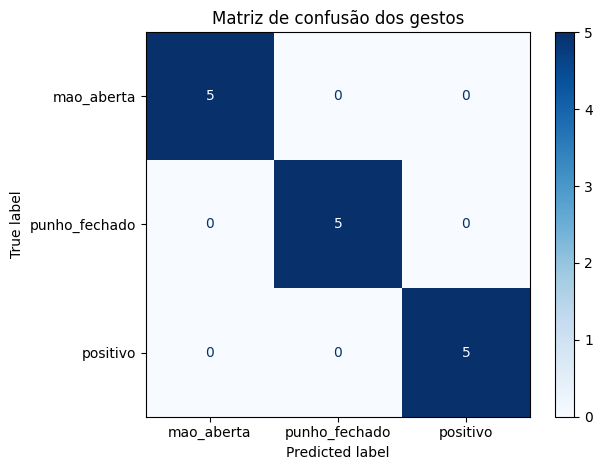

Relatório de classificação:
               precision    recall  f1-score   support

   mao_aberta      1.000     1.000     1.000         5
punho_fechado      1.000     1.000     1.000         5
     positivo      1.000     1.000     1.000         5

     accuracy                          1.000        15
    macro avg      1.000     1.000     1.000        15
 weighted avg      1.000     1.000     1.000        15



In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

classes = ["mao_aberta", "punho_fechado", "positivo"]

reais = tabela_avaliacao["gesto_real"]
previstos = tabela_avaliacao["gesto_previsto"]

matriz = confusion_matrix(
    reais,
    previstos,
    labels=classes
)

exibicao = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=classes
)

exibicao.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusão dos gestos")
plt.tight_layout()
plt.show()

print("Relatório de classificação:")
print(
    classification_report(
        reais,
        previstos,
        labels=classes,
        zero_division=0,
        digits=3
    )
)


### Avaliação do modelo

O sistema foi avaliado utilizando 15 imagens próprias, distribuídas igualmente entre três classes: mão aberta, punho fechado e polegar para cima. O MediaPipe detectou uma mão em todas as 15 imagens, correspondendo a uma taxa de detecção de 100% nesse conjunto.

O classificador baseado em regras geométricas obteve 15 acertos em 15 exemplos, com acurácia de 100%. As métricas de precisão, revocação (recall) e F1-score também foram iguais a 1,000 para as três classes.

Esses resultados devem ser interpretados com cautela, pois as regras foram desenvolvidas considerando as características observadas nas próprias imagens avaliadas. Dessa forma, o experimento demonstra a viabilidade da abordagem nesse conjunto inicial, mas não comprova sua capacidade de generalização para imagens inéditas.

Uma avaliação futura deverá utilizar novas fotografias, capturadas em diferentes condições de iluminação, distância, orientação e enquadramento. Também será importante separar os exemplos utilizados para desenvolver as regras daqueles utilizados exclusivamente para testar o desempenho.

### Avaliação do aplicativo móvel

O aplicativo foi testado com as mesmas 15 imagens, sendo cinco de cada classe: mão aberta, polegar para cima e punho fechado. Foram considerados acertos somente os casos em que o gesto previsto correspondia à classe esperada.

| Gesto esperado|Resultado correto |Erros ou falhas |
|---------------|------------------|----------------|
|Mão aberta|5/5   |Nenhum            |
|Polegar para cima|4/5            |1 imagem sem detecção |
|Punho fechado|2/5|2 classificados como polegar para cima e 1 sem detecção|
|**Total** | 11/15|  4 casos incorretos|

A acurácia observada no aplicativo foi de 73,3% (11 acertos em 15 imagens).

Os resultados indicam melhor desempenho no reconhecimento da mão aberta. As principais dificuldades ocorreram na distinção entre punho fechado e polegar para cima, além de dois casos em que nenhuma mão foi detectada.

A avaliação é exploratória e utiliza apenas 15 imagens. Assim, os resultados não devem ser generalizados para outras pessoas, condições de iluminação, ângulos ou fundos sem testes adicionais.



### Comparação entre as implementações

O classificador do notebook e o aplicativo móvel apresentaram resultados diferentes. Essa diferença deve ser analisada considerando suas implementações e regras de decisão. O resultado de 100% no notebook não deve ser interpretado como prova de desempenho superior em imagens novas, especialmente porque as regras foram ajustadas com base no conjunto avaliado.

## 6. Ética

As imagens utilizadas neste projeto foram produzidas pela própria autora, evitando a utilização não autorizada de fotografias de terceiros. As mãos foram utilizadas como objeto de análise, sem a necessidade de identificar pessoas.

O projeto tem finalidade educacional e não busca reconhecer a identidade de indivíduos. Recomenda-se evitar a publicação desnecessária de imagens pessoais, informar os usuários sobre o processamento realizado e limitar o armazenamento dos dados ao necessário para o experimento.

O sistema apresenta limitações e pode falhar quando a mão está parcialmente oculta, fora do enquadramento ou em condições desfavoráveis de iluminação. Portanto, seus resultados não devem ser considerados infalíveis.

## 7. Conclusão

O projeto demonstrou a utilização do MediaPipe Hand Landmarker para detectar mãos e extrair 21 pontos de referência em imagens. A partir desses pontos, foram calculadas medidas geométricas utilizadas por um classificador baseado em regras para distinguir três gestos: mão aberta, punho fechado e polegar para cima.

Na avaliação exploratória do classificador implementado no notebook, foram obtidos 15 acertos em 15 imagens. Entretanto, o aplicativo móvel apresentou 11 acertos em 15 imagens, correspondendo a uma acurácia de 73,3%. Os resultados evidenciam diferenças entre as implementações e indicam dificuldades principalmente na distinção entre punho fechado e polegar para cima, além de casos em que a mão não foi detectada.

Apesar dos resultados obtidos, o conjunto reduzido de imagens e a utilização dos mesmos exemplos durante o desenvolvimento das regras limitam as conclusões sobre a capacidade de generalização do sistema. Como trabalhos futuros, propõe-se ampliar a base de imagens, realizar testes com exemplos inéditos, avaliar diferentes condições de iluminação e posicionamento das mãos e aprimorar as regras de classificação para reduzir os erros observados.